# Fleet orchestration with Strands Agents, Amazon Bedrock AgentCore and AWS IoT Core

One goal in plain language. A Strands Agents planner on Amazon Bedrock AgentCore Runtime splits it across a robot
fleet by what each robot can do and where it stands. Commands reach the robots through AWS IoT Core. The control loop
and the safety rules stay on each robot.

This notebook walks through the pattern step by step. It runs the inspection cell
(a ROS 2 arm on mock hardware) and the yard (a MuJoCo simulation). The packing cell needs two real SO-101 arms; its
code is in `so101/`, and Step 7 shows how to add it.

**What is simulated.** The yard robots (three Pollen Robotics Microducks and a Unitree G1) are MuJoCo simulations. Their
motion comes from trained policies that run on each robot host: Pollen's Microduck ONNX skills and the G1 holosoma
walk, loaded through the open-source strands-robots library, used here only as the simulator. Every outcome below is
measured from the simulation, not taken from a status message.

**Before you run it,** follow the setup in `README.md` in this folder: create the operator key, deploy the planner,
and start the ROS 2 arm.

In [1]:
import json, os, subprocess, sys, threading, time, uuid
HERE = os.getcwd()                                    # run the notebook from the sample/ folder
sys.path[:0] = [f"{HERE}/fleet", f"{HERE}/yard"]
os.environ.setdefault("MUJOCO_GL", "cgl" if sys.platform == "darwin" else "egl")
import boto3
import imageio.v2 as imageio
import numpy as np
from botocore.config import Config
from cryptography.hazmat.primitives import serialization
from IPython.display import Image as Img, Video, display
from PIL import Image, ImageDraw, ImageFont
from strands_robots import Robot, Simulation          # the yard simulator only
from site_runner import Switchboard                    # one stepping loop for the shared simulated yard
import robot_host
from robot_host import Device, serve, QUIET_S, MAX_S
robot_host.print = lambda *a, **k: None   # keep the robot hosts' per-request log lines out of the notebook
from planner import Fleet
from iotlink import Link

REGION, TENANT = os.environ.get("AWS_REGION", "us-west-2"), "site"
PLANNER_ARN = open(f"{HERE}/runtime_arn.txt").read().strip()
KEY = serialization.load_pem_private_key(open(f"{HERE}/fleet/operator_key.pem", "rb").read(), None)   # the operator's, never the planner's
PUB = KEY.public_key().public_bytes(serialization.Encoding.Raw, serialization.PublicFormat.Raw).hex()
os.makedirs("media", exist_ok=True)
print("planner runtime:", PLANNER_ARN.split("/")[-1], "| watchdog quiet limit", QUIET_S, "s | longest motion", MAX_S, "s")

planner runtime: fleet_planner-SZw1gX3hC0 | watchdog quiet limit 1.5 s | longest motion 30.0 s


## Step 1: Set up

Follow `README.md` in this folder for the installs, the operator key, the planner deploy and the ROS 2 arm. The cell above loads what they created.

![architecture](architecture.png)

Before starting, check that no other yard is online in this tenant, so two fleets don't mix.

In [2]:
watch = Fleet(TENANT)
t0 = time.time()
while True:
    others = [d["device"] for d in watch.devices(timeout=4.0) if d["device"].startswith(("duck-", "g1-"))]
    if not others or time.time() - t0 > 600:
        break
    time.sleep(10)
print("yard robots already online:", others or "none")
print("other robots online now:", sorted(d["device"] for d in watch.devices(timeout=1.0)))
watch.close()
assert not others, "another yard is online in this tenant; rerun when it has left"

yard robots already online: none
other robots online now: ['ros-arm']


## Step 2: Robots describe themselves

The yard has three zones: a dock (the yellow pad), a yard lane (the blue strip) and a yard bin (the green walled
area). Each robot is a `Device` with its own IoT Core connection. It announces its zone and its skills, and it
describes each skill: what it does and how long it may run. Each skill is a trained policy that runs on the robot and
ends with a check.

The yard robots only know the skills trained for them: walk, turn and kick for the Microduck, and walk for the G1. So
the yard jobs are those skills given site names. Guarding the dock is the G1 walking onto the dock pad. Patrolling
the lane is a walker walking along it. Delivering the yard part is a walker kicking the red ball into the yard bin.

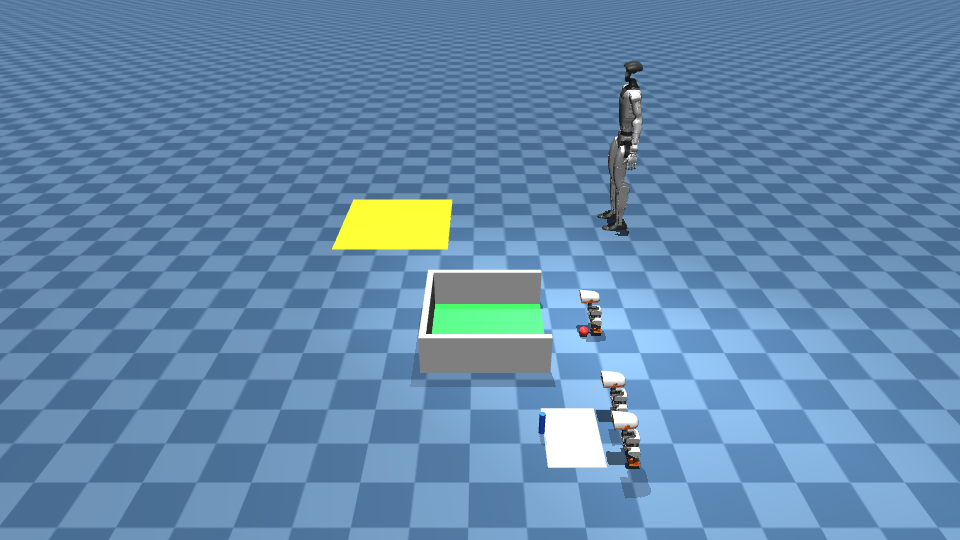

discovered over AWS IoT Core in 0.00 s:
  duck-1   zone yard-bin         skills ['kick', 'turn', 'walk']
  duck-2   zone yard-lane        skills ['kick', 'turn', 'walk']
  duck-3   zone yard-lane        skills ['kick', 'turn', 'walk']
  g1-1     zone dock             skills ['walk']
  ros-arm  zone inspection-cell  skills ['inspect', 'present']



what g1-1 says about its skill: {'walk': {'seconds': 4.0, 'does': 'walk about 1.7 m onto the dock pad and stand guard there'}}


what ros-arm says about its skills: {'inspect': {'seconds': 5.0, 'does': 'turn the part under the arm through a slow inspection sweep'}, 'present': {'seconds': 2.0, 'does': 'hold the part up to the inspection camera'}}


In [3]:
FONT, SMALL = ImageFont.load_default(size=22), ImageFont.load_default(size=18)
BIN, DOCK, LANE_Y, CHECK_X = (0.30, 1.0, -0.30, 0.40), (0.95, 1.85, -2.10, -1.10), 0.8, 0.33
ZONE = {"duck-1": "yard-bin", "duck-2": "yard-lane", "duck-3": "yard-lane", "g1-1": "dock"}
DUCK = {"walk": ("microduck?skill=velstand&vx=0.3", 4.0, "walk about 0.4 m along its lane, past the checkpoint"),
        "turn": ("microduck?skill=velstand&wz=1.2", 3.0, "turn on the spot"),
        "kick": ("microduck?skill=ball_kick_left", 2.0, "kick the part in front of its left foot into the yard bin")}
inside = lambda p, b: b[0] <= p[0] <= b[1] and b[2] <= p[1] <= b[3]


class SimBody:
    # What a Device needs from its body, for a simulated robot in the shared yard.
    def __init__(self, yard, did):
        self.yard, self.did, self.board = yard, did, yard["boards"][did]
        self.limits = {c.name.removesuffix(".pos"): tuple(round(float(v), 4) for v in c.range) for c in yard["robots"][did].manifest.controls}
    def positions(self):
        j = self.yard["robots"][self.did].observe(images=False).joints
        return {n: round(float(p), 4) for n, p in zip(j.names, j.positions)}
    def hold(self):
        self.board.stop("hold")          # a biped holds by standing: its stand policy keeps it balanced
    def command(self, targets):
        raise NotImplementedError("the yard robots move by skills only")
    def run_policy(self, spec, seconds, why_stop):
        self.board.start(spec, spec, seconds)
        while self.board.last.get("running"):
            why = why_stop()
            if why:
                self.hold(); return why
            time.sleep(0.02)
        return None


def build_yard():
    y = {"log": [], "offline": set(), "bin": {"at": None, "t": None, "watch": None}}
    w = y["world"] = Simulation("mujoco", render_size=(960, 540))
    with w.editing():
        y["robots"] = {d: Robot("microduck", id=d, sim=w) for d in ("duck-1", "duck-2", "duck-3")} | {"g1-1": Robot("g1", id="g1-1", sim=w)}
        flat = lambda n, x0, x1, y0, y1, c: w.add_object(n, shape="box", position=((x0 + x1) / 2, (y0 + y1) / 2, -0.0015),
                                                        size=((x1 - x0) / 2, (y1 - y0) / 2, 0.002), color=c, free=False)
        flat("yard_bin", *BIN, (0.2, 0.75, 0.3, 1)); flat("dock_pad", *DOCK, (0.95, 0.8, 0.15, 1))
        flat("patrol_lane", 0.10, CHECK_X + 0.05, LANE_Y - 0.06, LANE_Y + 0.36, (0.55, 0.65, 0.8, 1))
        for n, pos, size in (("bin_back", (1.02, 0.05, 0.12), (0.02, 0.39, 0.12)), ("bin_left", (0.67, 0.42, 0.12), (0.37, 0.02, 0.12)),
                             ("bin_right", (0.67, -0.32, 0.12), (0.37, 0.02, 0.12))):
            w.add_object(n, shape="box", position=pos, size=size, color=(0.85, 0.85, 0.85, 1), free=False)
        w.add_object("checkpoint", shape="cylinder", position=(CHECK_X + 0.06, LANE_Y + 0.12, 0.06), size=(0.015, 0.06), color=(0.15, 0.35, 0.95, 1), free=False)
        w.add_object("part", shape="sphere", position=(0.06, 0.064, 0.03), size=0.03, mass=0.02, color=(0.95, 0.2, 0.2, 1))
        w.light("sun", position=(1.0, -2.0, 4.0), directional=True)
        w.camera("overview", position=(0.7, 3.4, 2.3), target=(0.7, -0.5, 0.15))
        w.camera("walkers", position=(-0.75, 0.5, 0.95), target=(0.5, 0.45, 0.02))
    w.set_pose("duck-2", position=(0.0, LANE_Y, 0.12)); w.set_pose("duck-3", position=(0.0, LANE_Y + 0.3, 0.12))
    w.set_pose("g1-1", position=(-0.45, -1.6, 0.79))
    y["boards"] = {d: Switchboard(r, "holosoma" if d == "g1-1" else "microduck?skill=velstand") for d, r in y["robots"].items()}
    pos = y["pos"] = lambda d: y["robots"][d].observe(images=False).pose.position
    y["lane0"] = {d: float(pos(d)[0]) for d in ("duck-2", "duck-3")}

    def watch_bin(seconds=6.0):      # delivered = the part crosses into the bin (in this simulator a ball keeps rolling)
        t0 = time.perf_counter()
        while time.perf_counter() - t0 < seconds:
            p = w.pose("part").position
            if inside(p, BIN) and y["bin"]["at"] is None:
                y["bin"]["at"] = (round(time.perf_counter() - t0, 2), [round(float(v), 2) for v in p[:2]]); y["bin"]["t"] = y["now"]()
            time.sleep(0.02)

    def bin_check():
        y["bin"]["watch"].join(); e = y["bin"]["at"]
        return {"ok": e is not None, "in_bin_after_s": e[0] if e else None, "entered_at": e[1] if e else None}

    def dock_check():
        p = pos("g1-1"); return {"ok": bool(inside(p, DOCK) and p[2] > 0.6), "at": [round(float(v), 2) for v in p[:2]], "z": round(float(p[2]), 2)}

    lane = lambda d: (lambda: {"ok": bool(pos(d)[0] - y["lane0"][d] >= CHECK_X - 0.05), "advanced_m": round(float(pos(d)[0] - y["lane0"][d]), 2)})
    checks = {"duck-1": {"kick": bin_check}, "duck-2": {"walk": lane("duck-2")}, "duck-3": {"walk": lane("duck-3")}, "g1-1": {"walk": dock_check}}

    def skills_for(d):
        if d == "g1-1":
            return {"walk": {"policy": "holosoma?vx=0.5", "seconds": 4.0, "does": "walk about 1.7 m onto the dock pad and stand guard there", "check": dock_check}}
        return {k: {"policy": p, "seconds": s, "does": a, **({"check": checks[d][k]} if k in checks[d] else {})} for k, (p, s, a) in DUCK.items()}

    y["devices"] = {d: Device(SimBody(y, d), d, ZONE[d], skills_for(d), PUB) for d in y["robots"]}
    y["stops"] = {d: threading.Event() for d in y["robots"]}
    y["t0"] = time.perf_counter(); y["now"] = lambda: round(time.perf_counter() - y["t0"], 2)
    for d, dev in y["devices"].items():       # log every dispatch, and start the bin watcher when a kick starts
        orig = dev._start
        def logged(name, moves, by, policy=None, _orig=orig, _d=d):
            if _d == "duck-1" and name == "kick":
                y["bin"].update(at=None, t=None); y["bin"]["watch"] = threading.Thread(target=watch_bin, daemon=True); y["bin"]["watch"].start()
            out = _orig(name, moves, by, policy)
            y["log"].append({"t": y["now"](), "dispatched": name, "to": _d})
            if y.get("cut") and _d in ("duck-2", "duck-3") and name == "walk" and not y["offline"]:
                def cut():      # this robot host loses its network: no presence, no rpcs, no planner heartbeats
                    y["log"].append({"t": y["now"](), "offline": _d}); y["offline"].add(_d); y["stops"][_d].set()
                threading.Timer(1.0, cut).start()
            return out
        dev._start = logged
        threading.Thread(target=serve, args=(dev, TENANT, y["stops"][d]), daemon=True).start()
    threading.Thread(target=lambda: w.run(dict(zip(y["robots"].values(), y["boards"].values())), seconds=900.0), daemon=True).start()
    return y


def close_yard(y):
    for e in y["stops"].values():
        e.set()
    time.sleep(4.0)       # presence ends: the planner sees these robots leave


yard = build_yard()
imageio.imwrite("media/yard.png", yard["world"].render("overview"))
display(Img("media/yard.png", width=640))
fleet = Fleet(TENANT)
ROBOTS = {"duck-1", "duck-2", "duck-3", "g1-1", "ros-arm"}
t0 = time.perf_counter()
while not ROBOTS <= {d["device"] for d in fleet.devices(timeout=0.5)} and time.perf_counter() - t0 < 30:
    time.sleep(0.1)
online = {d["device"]: d for d in fleet.devices()}
print(f"discovered over AWS IoT Core in {time.perf_counter() - t0:.2f} s:")
for d in sorted(online):
    print(f"  {d:8s} zone {online[d]['zone']:16s} skills {online[d]['skills']}")
assert ROBOTS <= set(online), f"missing: {ROBOTS - set(online)} (is the ros-arm container running?)"
call = fleet.link.call
print("\nwhat g1-1 says about its skill:", call("g1-1", "describe")["skills"])
print("what ros-arm says about its skills:", call("ros-arm", "describe")["skills"])

## Step 3: The five rules, live over AWS IoT Core

Each check below goes over the network to a robot and back. The planner's side is a `Fleet`: an IoT Core client that
hears each robot announce itself every second and sends it requests.

In [4]:
def refused(fn, *a, **k):
    try:
        fn(*a, **k); return "NOT refused"
    except (RuntimeError, ConnectionError) as e:
        return str(e)[:150]

# Rule 1: a target outside a joint's limits is refused, never clamped, and nothing moves.
j, (lo, hi) = next(iter(yard["devices"]["duck-3"].describe()["joints"].items()))
print("rule 1:", refused(call, "duck-3", "act", targets={j: hi + 1.0}, seconds=1.0))
print("        motion started:", call("duck-3", "status"))
# Rule 5: skills are named and bounded; a robot runs only the skills it offers.
print("rule 5:", refused(call, "duck-3", "skill", name="fly"))

rule 1: duck-3 refused act: ValueError: left_hip_yaw=1.5236 is outside its range [-0.4363, 0.5236]; refused, nothing moved


        motion started: {'name': None, 'running': False}


rule 5: duck-3 refused skill: LookupError: no skill 'fly'; this robot offers ['kick', 'turn', 'walk']


### Stop a robot, and resume it

Rules 2 and 3. An e-stop latches, and every motion is refused until a person resumes the robot. The planner can stop a
robot but can't resume one: it has no resume tool, and its IAM role is denied the resume topic and the approval topic.
The operator resumes with a signature over this robot and this stop, which is what `fleet/resume.py` sends.

This is a software stop. Keep the robot's hardware e-stop as well.

In [5]:
t = time.perf_counter(); e = call("duck-3", "estop"); print(f"rule 2: e-stop acknowledged in {time.perf_counter() - t:.3f} s, latched")
print("        a skill while latched:", refused(call, "duck-3", "skill", name="turn"))
print("rule 3: an unsigned resume:", refused(call, "duck-3", "resume", operator="planner"))
print("        the planner's tools:", [t.tool_name for t in fleet.tools()])
acct = boto3.client("sts").get_caller_identity()["Account"]
for topic in (f"{TENANT}/duck-3/rpc/resume", f"{TENANT}/arm-1/approval", f"{TENANT}/duck-3/rpc/estop", f"{TENANT}/duck-3/rpc/skill"):
    r = boto3.client("iam").simulate_principal_policy(
        PolicySourceArn=f"arn:aws:iam::{acct}:role/fleet-planner-runtime", ActionNames=["iot:Publish"],
        ResourceArns=[f"arn:aws:iot:{REGION}:{acct}:topic/{topic}"])["EvaluationResults"][0]
    print(f"        may the planner's role publish {topic}? {r['EvalDecision']}")
# What fleet/resume.py does: read this stop's epoch, sign it with the operator's key, send the resume.
ep = call("duck-3", "epoch")
print("        the operator's signed resume:", call("duck-3", "resume", operator="operator", signature=KEY.sign(f"duck-3:{ep['epoch']}".encode()).hex()))

rule 2: e-stop acknowledged in 0.282 s, latched


        a skill while latched: duck-3 refused skill: PermissionError: e-stop is latched; an operator must resume this robot


rule 3: an unsigned resume: duck-3 refused resume: PermissionError: resume needs the operator's signature for this stop; refused
        the planner's tools: ['list_devices', 'describe', 'run_skill', 'run_sequence', 'act', 'skill_status', 'wait_for_skill', 'emergency_stop']


        may the planner's role publish site/duck-3/rpc/resume? explicitDeny


        may the planner's role publish site/arm-1/approval? explicitDeny


        may the planner's role publish site/duck-3/rpc/estop? allowed


        may the planner's role publish site/duck-3/rpc/skill? allowed


        the operator's signed resume: {'estopped': False, 'resumed_by': 'operator'}


### The watchdog

Rule 4. A commander starts a 4 s walk, then goes quiet. The robot stops hearing its heartbeat and holds, instead of
walking on.

In [6]:
x0 = float(yard["pos"]("duck-3")[0])
quiet = Link(f"planner-quiet-{uuid.uuid4().hex[:6]}", TENANT)
quiet.publish(f"{TENANT}/heartbeat/{quiet.client_id}", {"ts": time.time()}); time.sleep(0.3)
quiet.call("duck-3", "skill", name="walk"); time.sleep(0.8); quiet.close()
while call("duck-3", "status")["running"]:
    time.sleep(0.2)
st = call("duck-3", "status")
print("rule 4:", st["stopped_by"], f"| walked {float(yard['pos']('duck-3')[0]) - x0:.2f} m of a 4 s walk (about 0.4 m when it runs to the end)")
yard["lane0"]["duck-3"] = float(yard["pos"]("duck-3")[0])    # the lane check measures from where duck-3 stands now

rule 4: watchdog: commander went quiet, holding | walked 0.14 m of a 4 s walk (about 0.4 m when it runs to the end)


## Step 4: Run the morning shift

One goal, in plain language, through the planner on AgentCore Runtime. It names no robot and no skill. The planner
reads zones and skill descriptions, assigns the work, runs it in parallel, waits, and reports what each robot's check
measured. The client waits up to 15 minutes and never retries, so a long goal is never sent twice.

With the SO-101 arms on the fleet, the goal starts with the packing cell (Step 7).

In [7]:
GOAL = ("Start the morning shift. In the inspection cell, show the part to the camera. In the yard, guard the dock, "
        "patrol the yard lane, and kick the yard part into the yard bin. Unload the truck. Robots may work at the same time.")
agentcore = boto3.client("bedrock-agentcore", region_name=REGION, config=Config(read_timeout=900, retries={"total_max_attempts": 1}))

def label(img, text):
    im = Image.fromarray(img); dr = ImageDraw.Draw(im); dr.rectangle([0, 0, im.width, 30], fill=(20, 24, 32)); dr.text((10, 5), text, fill=(240, 240, 240), font=SMALL)
    return np.asarray(im)

def run_goal(y, tag, cut=False):
    y["cut"], y["log"], y["offline"] = cut, [], set()
    frames, stop, done = [], threading.Event(), [None]
    y["t0"] = time.perf_counter()
    def film():
        while not stop.is_set():
            st = {d: y["devices"][d].status() for d in y["robots"]}
            tags = "   ".join(f"{d}: " + ("offline" if d in y["offline"] else (st[d]["name"] if st[d].get("running") else "idle")) for d in y["robots"])
            row = np.hstack([label(y["world"].render("overview"), "yard overview   |   " + tags), label(y["world"].render("walkers"), "close-up: walkers")])
            e, busy = (y["log"][-1] if y["log"] else None), any(s.get("running") for s in st.values())
            inbin = f"   |   part in the bin at t = {y['bin']['t']:.1f} s" if y["bin"]["t"] is not None else ""
            stage = (f"planner finished at {done[0]:.1f} s and reported back" if done[0] is not None and not busy else
                     "planner: discovering robots over AWS IoT Core and planning" if e is None else
                     f"{e['offline']} lost its network connection" if "offline" in e else f"planner dispatched '{e['dispatched']}' to {e['to']} (the robot runs the policy)")
            ban = Image.new("RGB", (row.shape[1], 40), (12, 14, 20))
            ImageDraw.Draw(ban).text((12, 8), f"t = {y['now']():5.1f} s  |  Strands agent on Amazon Bedrock AgentCore Runtime  |  {stage}{inbin}", fill=(255, 210, 90), font=FONT)
            frames.append((y["now"](), np.vstack([np.asarray(ban), row]))); time.sleep(0.1)
    th = threading.Thread(target=film, daemon=True); th.start()
    r = agentcore.invoke_agent_runtime(agentRuntimeArn=PLANNER_ARN, runtimeSessionId=f"shift-{uuid.uuid4().hex}",
                                       payload=json.dumps({"prompt": GOAL, "min_devices": 5}).encode())
    out = json.loads(r["response"].read()); done[0] = y["now"]()
    t_end = time.perf_counter()
    while any(dev.status().get("running") for dev in y["devices"].values()) and time.perf_counter() - t_end < 10:
        time.sleep(0.2)
    time.sleep(1.5); stop.set(); th.join()
    ts = [t for t, _ in frames]   # rendering runs slower than real time: resample by timestamp so the clip plays in real time
    real = [frames[max(0, np.searchsorted(ts, k / 10, side="right") - 1)][1] for k in range(int(ts[-1] * 10) + 1)]
    imageio.mimsave(f"media/{tag}.mp4", real, fps=10, codec="libx264", quality=7, macro_block_size=8)
    end = {d: y["pos"](d) for d in y["robots"]}
    outcome = {"part_in_bin": y["bin"]["at"], "g1_on_dock": dict(at=[round(float(v), 2) for v in end["g1-1"][:2]], z=round(float(end["g1-1"][2]), 2),
               ok=bool(inside(end["g1-1"], DOCK) and end["g1-1"][2] > 0.6)),
               "lane_advanced_m": {d: round(float(end[d][0] - y["lane0"][d]), 2) for d in ("duck-2", "duck-3")},
               "stopped_by": {d: y["devices"][d].status().get("stopped_by") for d in y["robots"]},
               # the ROS 2 arm's joints, read from its own /joint_states inside its container (command path, mock hardware)
               "ros_arm_joints": subprocess.run(["docker", "exec", "ros-arm", "bash", "-lc",
                                                "source /opt/ros/jazzy/setup.bash && /venv/bin/python /ros2/ros_read.py"],
                                                  capture_output=True, text=True).stdout.strip()[-200:]}
    return out, outcome, f"media/{tag}.mp4", round(len(frames) / ts[-1], 1)

out, outcome, clip, fps = run_goal(yard, "shift")
print(f"planner: discovery {out['discover_s']} s, handler {out['total_s']} s, errors {out['errors']}")
for c in out["calls"]:
    if c["tool"] in ("run_skill", "skill"):
        print("  skill", c.get("device"), c.get("skill") or c.get("name"))
print("dispatch log:", yard["log"])
print("ledger, skills each robot was sent:", out["ledger_skills_sent"])
print("measured:", json.dumps(outcome))
print(f"(rendered at {fps} frames per wall second, resampled to real time)")
print()
print(out["reply"])
display(Video(clip, width=960, embed=True))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=8, resizing from (1920, 580) to (1920, 584) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


planner: discovery 0.0 s, handler 24.28 s, errors []
  skill ros-arm present
  skill g1-1 walk
  skill duck-2 walk
  skill duck-1 kick
dispatch log: [{'t': 10.35, 'dispatched': 'walk', 'to': 'duck-2'}, {'t': 10.37, 'dispatched': 'walk', 'to': 'g1-1'}, {'t': 10.39, 'dispatched': 'kick', 'to': 'duck-1'}]
ledger, skills each robot was sent: {'ros-arm': ['present'], 'g1-1': ['walk'], 'duck-2': ['walk'], 'duck-1': ['kick']}
measured: {"part_in_bin": [0.97, [0.31, 0.16]], "g1_on_dock": {"at": [1.14, -1.45], "z": 0.77, "ok": true}, "lane_advanced_m": {"duck-2": 0.38, "duck-3": -0.0}, "stopped_by": {"duck-1": "done", "duck-2": "done", "duck-3": "watchdog: commander went quiet, holding", "g1-1": "done"}, "ros_arm_joints": "{\"j1\": 0.0, \"j2\": 0.6, \"j3\": -0.6, \"j4\": 0.0}"}
(rendered at 3.0 frames per wall second, resampled to real time)

Three of the four tasks are done. I couldn't do the truck unload, because no robot has an unload skill.

- **Inspection cell:** `ros-arm` ran `present` an

## Step 5: Finished is not done

A skill can run to its end without achieving its purpose. Here the part is moved off its spot before the kick. The
kick finishes, and the robot's check says the part didn't reach the bin. The planner reports what the check saw, not
that the skill finished.

In [8]:
yard["world"].set_pose("part", position=(0.06, -0.25, 0.03))     # off the kicking foot
call("duck-1", "skill", name="kick")
while call("duck-1", "status")["running"]:
    time.sleep(0.2)
st = call("duck-1", "status")
print("kick stopped_by:", st["stopped_by"], "| check:", st.get("check"))

kick stopped_by: done | check: {'ok': False, 'in_bin_after_s': None, 'entered_at': None}


## Step 6: A robot drops off the network

The same goal, in a fresh yard. One second into the lane patrol, that walker's robot host loses its network. On the
robot, the watchdog stops hearing the planner's heartbeat and holds it. The planner gets no answer: the outcome is
unknown, and it says so. Only a robot in the same zone can take the task over, so it gives the patrol to the other
walker in the yard lane.

In [9]:
close_yard(yard)
yard = build_yard(); time.sleep(3.0)
out2, outcome2, clip2, fps2 = run_goal(yard, "dropout", cut=True)
print(f"planner: handler {out2['total_s']} s, errors {out2['errors']}")
print("dispatch log:", yard["log"])
print("measured:", json.dumps(outcome2))
print()
print(out2["reply"])
display(Video(clip2, width=960, embed=True))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=8, resizing from (1920, 580) to (1920, 584) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


planner: handler 40.79 s, errors ['Error: ConnectionError - duck-2 did not answer status within 6 s (offline or unreachable); nothing was queued']
dispatch log: [{'t': 8.01, 'dispatched': 'walk', 'to': 'duck-2'}, {'t': 8.06, 'dispatched': 'kick', 'to': 'duck-1'}, {'t': 8.07, 'dispatched': 'walk', 'to': 'g1-1'}, {'t': 9.02, 'offline': 'duck-2'}, {'t': 24.64, 'dispatched': 'walk', 'to': 'duck-3'}]
measured: {"part_in_bin": [1.48, [0.3, 0.16]], "g1_on_dock": {"at": [1.22, -1.55], "z": 0.76, "ok": true}, "lane_advanced_m": {"duck-2": 0.04, "duck-3": 0.4}, "stopped_by": {"duck-1": "done", "duck-2": "watchdog: commander went quiet, holding", "duck-3": "done", "g1-1": "done"}, "ros_arm_joints": "{\"j1\": 0.0, \"j2\": 0.6, \"j3\": -0.6, \"j4\": 0.0}"}

Three of the four tasks are done, and no robot can unload the truck.

- **Inspection cell:** Done. `ros-arm` ran `present` and held the part up to the camera. Its check passed.
- **Dock guard:** Done. `g1-1` walked onto the dock pad. Its check p

## Step 7: The same pattern on real arms

The packing cell is the same robot host with a LeRobot SO-101 body and one skill, `pick`, an ACT policy that runs on
the robot host. Each arm stands in its own zone (`black-parts`, `blue-parts`) because each policy picks from one fixed
spot. A pick waits for the operator's signed approval before the arm moves. This part needs the arms, so it is not run
here. With the arms connected:

    cp so101/arms.example.json so101/arms.json          # your ports, calibration ids and camera indices
    ARM=arm-1 python so101/arm_host.py --preflight      # read-only check, zero writes to the motors
    ARM=arm-1 python so101/arm_host.py                  # and ARM=arm-2 in a second terminal
    python fleet/send_goal.py "Start the morning shift. In the packing cell, pack one black part and one blue part; the two arms share one bin, so only one arm at a time. ..."
    python fleet/approve.py arm-1                       # when arm-1 asks; then arm-2

`so101/JETSON.md` runs one arm's host on an NVIDIA Jetson Orin Nano instead of a laptop.

## Clean up

In [10]:
close_yard(yard)
fleet.close()
print("yard robots left the fleet; planner client closed")
print("next: python planner_runtime/teardown.py, then docker rm -f ros-arm")

yard robots left the fleet; planner client closed
next: python planner_runtime/teardown.py, then docker rm -f ros-arm
